In [1]:

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split, KFold
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tabulate import tabulate

warnings.filterwarnings("ignore")



In [2]:
df = pd.read_csv("ThucHanhSVM.csv", delimiter=",", skipinitialspace=True)
print("=== Y 1: DU LIEU BAN DAU ===")
display(df)

=== Y 1: DU LIEU BAN DAU ===


,A,B,C,D,E,F,G,Class
0,9.0,15.0,3.7,2.9,1.2,5.9,4.0,P
1,3.5,4.5,3.1,2.5,2.8,10.0,6.7,N
2,4.1,4.9,2.1,3.7,2.5,10.0,3.3,P
3,4.6,3.5,2.5,2.2,2.7,11.0,7.2,P
4,5.6,1.6,4.1,3.9,4.7,5.6,2.9,N
5,5.7,3.9,2.6,5.8,2.3,4.6,3.6,P
6,8.9,2.5,2.4,3.5,1.6,9.5,2.8,P
7,2.9,3.2,2.9,3.9,3.9,10.6,4.0,P
8,2.2,2.2,3.9,13.4,2.2,11.3,2.9,N
9,6.3,4.1,2.4,12.1,1.8,2.7,4.0,P


In [3]:
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
sym_cols = df.select_dtypes(include=["object", "category", "string"]).columns.tolist()

if sym_cols:
    df[sym_cols] = df[sym_cols].apply(lambda col: LabelEncoder().fit_transform(col))
    df[sym_cols] = df[sym_cols].astype("int")

if num_cols:
    scaler = MinMaxScaler()
    df[num_cols] = scaler.fit_transform(df[num_cols])

print("\n=== DU LIEU SAU CHUAN HOA ===")
display(df.round(4))

df_X = df[df.columns[:-1]].values
df_y = df[df.columns[-1]].values


=== DU LIEU SAU CHUAN HOA ===


,A,B,C,D,E,F,G,Class
0,1.0000,1.0000,0.80,0.0625,0.000,0.3721,0.3043,1
1,0.1912,0.2164,0.50,0.0268,0.400,0.8488,0.8913,0
2,0.2794,0.2463,0.00,0.1339,0.325,0.8488,0.1522,1
3,0.3529,0.1418,0.20,0.0000,0.375,0.9651,1.0000,1
4,0.5000,0.0000,1.00,0.1518,0.875,0.3372,0.0652,0
5,0.5147,0.1716,0.25,0.3214,0.275,0.2209,0.2174,1
6,0.9853,0.0672,0.15,0.1161,0.100,0.7907,0.0435,1
7,0.1029,0.1194,0.40,0.1518,0.675,0.9186,0.3043,1
8,0.0000,0.0448,0.90,1.0000,0.250,1.0000,0.0652,0
9,0.6029,0.1866,0.15,0.8839,0.150,0.0000,0.3043,1


In [4]:
X_train_60, X_test_40, y_train_60, y_test_40 = train_test_split(
    df_X,
    df_y,
    test_size=0.4,
    random_state=0,
    shuffle=False,
)

print("\n=== Y 2: CHIA DU LIEU 60% TRAIN - 40% TEST ===")
print("Tap train dau vao x 60% :")
print(tabulate(X_train_60, tablefmt='grid', floatfmt=".4f"))
print("Tap train nhan y 60%:")
print(y_train_60)
print("Tap test dau vao x 40%:")
print(tabulate(X_test_40, tablefmt='grid', floatfmt=".4f"))
print("Tap test nhan y 40%:")
print(y_test_40)

k = 4
kf = KFold(n_splits=k, shuffle=False)

X_train_folds = []
y_train_folds = []
X_test_folds = []
y_test_folds = []

print("\n=== Y 3: CHIA DU LIEU THANH 4 FOLD ===")
for fold_idx, (train_index, test_index) in enumerate(kf.split(df_X, df_y), start=1):
    X_train_sub, X_test_sub = df_X[train_index], df_X[test_index]
    y_train_sub, y_test_sub = df_y[train_index], df_y[test_index]

    X_train_folds.append(X_train_sub)
    y_train_folds.append(y_train_sub)
    X_test_folds.append(X_test_sub)
    y_test_folds.append(y_test_sub)

    print(f"========================= FOLD {fold_idx} ============================")
    print("Tap huan luyen:")
    display(df.iloc[train_index].round(4))
    print("Tap kiem chung:")
    display(df.iloc[test_index].round(4))



=== Y 2: CHIA DU LIEU 60% TRAIN - 40% TEST ===
Tap train dau vao x 60% :
+--------+--------+--------+--------+--------+--------+--------+
| 1.0000 | 1.0000 | 0.8000 | 0.0625 | 0.0000 | 0.3721 | 0.3043 |
+--------+--------+--------+--------+--------+--------+--------+
| 0.1912 | 0.2164 | 0.5000 | 0.0268 | 0.4000 | 0.8488 | 0.8913 |
+--------+--------+--------+--------+--------+--------+--------+
| 0.2794 | 0.2463 | 0.0000 | 0.1339 | 0.3250 | 0.8488 | 0.1522 |
+--------+--------+--------+--------+--------+--------+--------+
| 0.3529 | 0.1418 | 0.2000 | 0.0000 | 0.3750 | 0.9651 | 1.0000 |
+--------+--------+--------+--------+--------+--------+--------+
| 0.5000 | 0.0000 | 1.0000 | 0.1518 | 0.8750 | 0.3372 | 0.0652 |
+--------+--------+--------+--------+--------+--------+--------+
| 0.5147 | 0.1716 | 0.2500 | 0.3214 | 0.2750 | 0.2209 | 0.2174 |
+--------+--------+--------+--------+--------+--------+--------+
| 0.9853 | 0.0672 | 0.1500 | 0.1161 | 0.1000 | 0.7907 | 0.0435 |
+--------+------

,A,B,C,D,E,F,G,Class
3,0.3529,0.1418,0.20,0.0000,0.375,0.9651,1.0000,1
4,0.5000,0.0000,1.00,0.1518,0.875,0.3372,0.0652,0
5,0.5147,0.1716,0.25,0.3214,0.275,0.2209,0.2174,1
6,0.9853,0.0672,0.15,0.1161,0.100,0.7907,0.0435,1
7,0.1029,0.1194,0.40,0.1518,0.675,0.9186,0.3043,1
8,0.0000,0.0448,0.90,1.0000,0.250,1.0000,0.0652,0
9,0.6029,0.1866,0.15,0.8839,0.150,0.0000,0.3043,1
10,0.0147,0.1119,0.70,0.0000,1.000,0.3605,0.0870,0
11,0.8235,0.0821,0.65,0.0446,0.975,0.0814,0.0000,1


Tap kiem chung:


,A,B,C,D,E,F,G,Class
0,1.0000,1.0000,0.8,0.0625,0.000,0.3721,0.3043,1
1,0.1912,0.2164,0.5,0.0268,0.400,0.8488,0.8913,0
2,0.2794,0.2463,0.0,0.1339,0.325,0.8488,0.1522,1


========================= FOLD 2 ============================
Tap huan luyen:


,A,B,C,D,E,F,G,Class
0,1.0000,1.0000,0.80,0.0625,0.000,0.3721,0.3043,1
1,0.1912,0.2164,0.50,0.0268,0.400,0.8488,0.8913,0
2,0.2794,0.2463,0.00,0.1339,0.325,0.8488,0.1522,1
6,0.9853,0.0672,0.15,0.1161,0.100,0.7907,0.0435,1
7,0.1029,0.1194,0.40,0.1518,0.675,0.9186,0.3043,1
8,0.0000,0.0448,0.90,1.0000,0.250,1.0000,0.0652,0
9,0.6029,0.1866,0.15,0.8839,0.150,0.0000,0.3043,1
10,0.0147,0.1119,0.70,0.0000,1.000,0.3605,0.0870,0
11,0.8235,0.0821,0.65,0.0446,0.975,0.0814,0.0000,1


... (6 outputs left out)

========================= FOLD 4 ============================
Tap huan luyen:


,A,B,C,D,E,F,G,Class
0,1.0000,1.0000,0.80,0.0625,0.000,0.3721,0.3043,1
1,0.1912,0.2164,0.50,0.0268,0.400,0.8488,0.8913,0
2,0.2794,0.2463,0.00,0.1339,0.325,0.8488,0.1522,1
3,0.3529,0.1418,0.20,0.0000,0.375,0.9651,1.0000,1
4,0.5000,0.0000,1.00,0.1518,0.875,0.3372,0.0652,0
5,0.5147,0.1716,0.25,0.3214,0.275,0.2209,0.2174,1
6,0.9853,0.0672,0.15,0.1161,0.100,0.7907,0.0435,1
7,0.1029,0.1194,0.40,0.1518,0.675,0.9186,0.3043,1
8,0.0000,0.0448,0.90,1.0000,0.250,1.0000,0.0652,0


Tap kiem chung:


,A,B,C,D,E,F,G,Class
9,0.6029,0.1866,0.15,0.8839,0.150,0.0000,0.3043,1
10,0.0147,0.1119,0.70,0.0000,1.000,0.3605,0.0870,0
11,0.8235,0.0821,0.65,0.0446,0.975,0.0814,0.0000,1


In [5]:

avg_mode = "binary" if len(np.unique(df_y)) == 2 else "weighted"

svm_accs, svm_precs, svm_recs, svm_f1s = [], [], [], []
nb_accs, nb_precs, nb_recs, nb_f1s = [], [], [], []

for i in range(k):
    clf_svm = SVC(kernel="rbf")

    clf_svm.fit(X_train_folds[i], y_train_folds[i])
    y_pred_svm = clf_svm.predict(X_test_folds[i])

    acc_svm = accuracy_score(y_test_folds[i], y_pred_svm)
    pre_svm = precision_score(y_test_folds[i], y_pred_svm, average=avg_mode, zero_division=0)
    rec_svm = recall_score(y_test_folds[i], y_pred_svm, average=avg_mode, zero_division=0)
    f1_svm = f1_score(y_test_folds[i], y_pred_svm, average=avg_mode, zero_division=0)

    svm_accs.append(acc_svm)
    svm_precs.append(pre_svm)
    svm_recs.append(rec_svm)
    svm_f1s.append(f1_svm)

    # --- Mo hinh Naive Bayes (GaussianNB) ---
    clf_nb = GaussianNB()

    clf_nb.fit(X_train_folds[i], y_train_folds[i])
    y_pred_nb = clf_nb.predict(X_test_folds[i])

    acc_nb = accuracy_score(y_test_folds[i], y_pred_nb)
    pre_nb = precision_score(y_test_folds[i], y_pred_nb, average=avg_mode, zero_division=0)
    rec_nb = recall_score(y_test_folds[i], y_pred_nb, average=avg_mode, zero_division=0)
    f1_nb = f1_score(y_test_folds[i], y_pred_nb, average=avg_mode, zero_division=0)

    nb_accs.append(acc_nb)
    nb_precs.append(pre_nb)
    nb_recs.append(rec_nb)
    nb_f1s.append(f1_nb)

    fold_data = [
        ["Mo hinh", "Accuracy (%)", "Precision (%)", "Recall (%)", "F1_score (%)"],
        ["SVM", f"{acc_svm * 100:.2f}", f"{pre_svm * 100:.2f}", f"{rec_svm * 100:.2f}", f"{f1_svm * 100:.2f}"],
        ["Naive Bayes", f"{acc_nb * 100:.2f}", f"{pre_nb * 100:.2f}", f"{rec_nb * 100:.2f}", f"{f1_nb * 100:.2f}"],
    ]
    print(f"\nSVM + Naive Bayes - FOLD {i + 1}")
    print(tabulate(fold_data, headers="firstrow", tablefmt="grid"))

summary_data = [
    ["Mo hinh", "Accuracy (%)", "Precision (%)", "Recall (%)", "F1_score (%)"],
    [
        "SVM",
        f"{np.mean(svm_accs) * 100:.2f}±{np.std(svm_accs) * 100:.2f}",
        f"{np.mean(svm_precs) * 100:.2f}±{np.std(svm_precs) * 100:.2f}",
        f"{np.mean(svm_recs) * 100:.2f}±{np.std(svm_recs) * 100:.2f}",
        f"{np.mean(svm_f1s) * 100:.2f}±{np.std(svm_f1s) * 100:.2f}",
    ],
    [
        "Naive Bayes",
        f"{np.mean(nb_accs) * 100:.2f}±{np.std(nb_accs) * 100:.2f}",
        f"{np.mean(nb_precs) * 100:.2f}±{np.std(nb_precs) * 100:.2f}",
        f"{np.mean(nb_recs) * 100:.2f}±{np.std(nb_recs) * 100:.2f}",
        f"{np.mean(nb_f1s) * 100:.2f}±{np.std(nb_f1s) * 100:.2f}",
    ],
]
print("\nSVM + Naive Bayes - SUMMARY 4-FOLD")
print(tabulate(summary_data, headers="firstrow", tablefmt="grid"))


SVM + Naive Bayes - FOLD 1
+-------------+----------------+-----------------+--------------+----------------+
| Mo hinh     |   Accuracy (%) |   Precision (%) |   Recall (%) |   F1_score (%) |
+=============+================+=================+==============+================+
| SVM         |          66.67 |           66.67 |          100 |             80 |
+-------------+----------------+-----------------+--------------+----------------+
| Naive Bayes |          66.67 |           66.67 |          100 |             80 |
+-------------+----------------+-----------------+--------------+----------------+

SVM + Naive Bayes - FOLD 2
+-------------+----------------+-----------------+--------------+----------------+
| Mo hinh     |   Accuracy (%) |   Precision (%) |   Recall (%) |   F1_score (%) |
+=============+================+=================+==============+================+
| SVM         |          66.67 |           66.67 |          100 |             80 |
+-------------+----------------

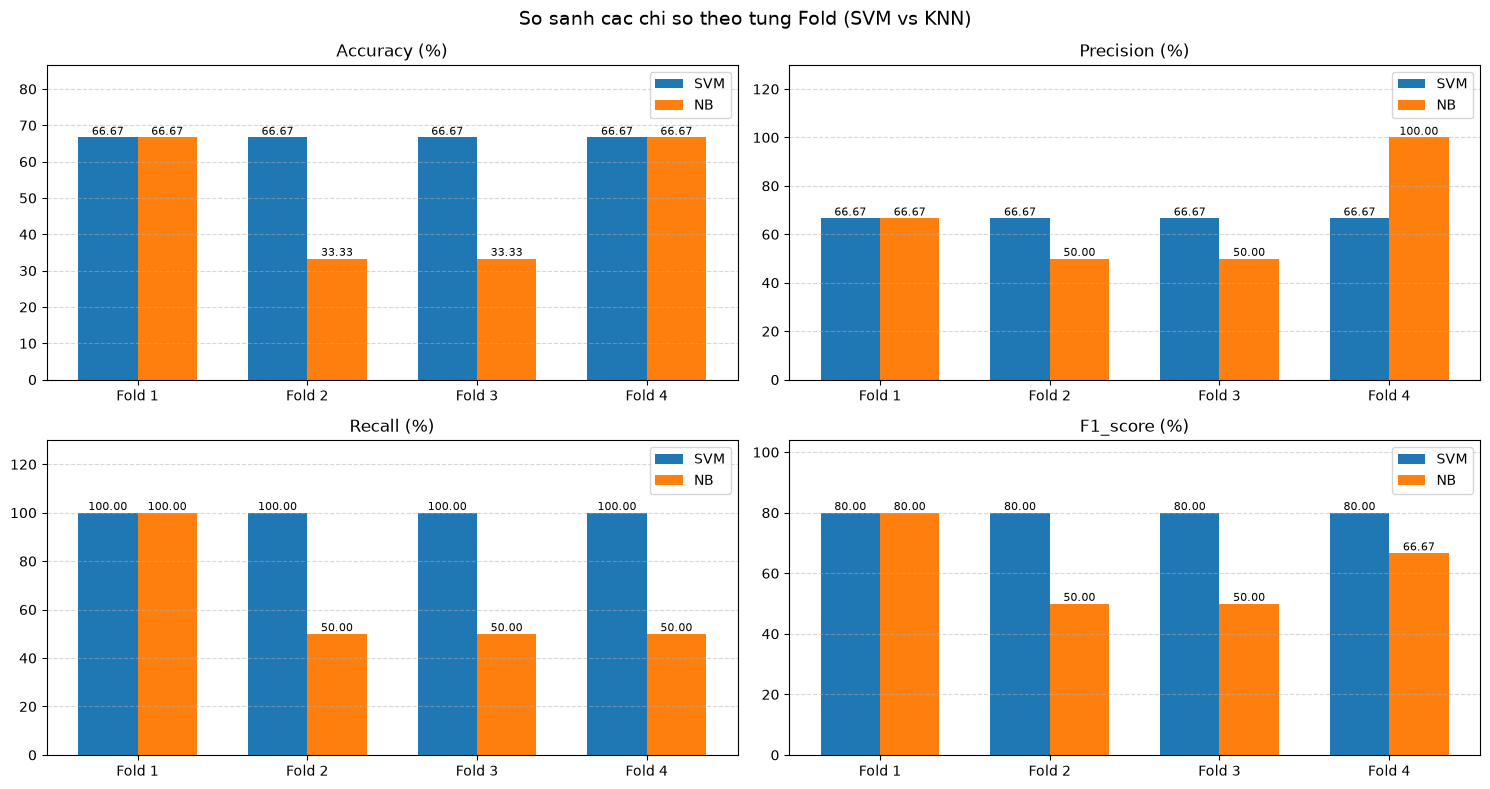

In [6]:
num_folds = len(svm_accs)
folds = np.arange(1, num_folds + 1)
w = 0.35

metrics = [
    ("Accuracy (%)", np.array(svm_accs) * 100, np.array(nb_accs) * 100, "{:.2f}"),
    ("Precision (%)", np.array(svm_precs) * 100, np.array(nb_precs) * 100, "{:.2f}"),
    ("Recall (%)", np.array(svm_recs) * 100, np.array(nb_recs) * 100, "{:.2f}"),
    ("F1_score (%)", np.array(svm_f1s) * 100, np.array(nb_f1s) * 100, "{:.2f}"),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

for i, (title, svm_val, nb_val, fmt) in enumerate(metrics):
    r, c = divmod(i, 2)
    ax = axes[r, c]

    p_svm = ax.bar(folds - w / 2, svm_val, width=w, label="SVM")
    p_nb = ax.bar(folds + w / 2, nb_val, width=w, label="NB")

    ax.set_title(title)
    ax.set_xticks(folds)
    ax.set_xticklabels([f"Fold {f}" for f in folds])
    ax.grid(axis="y", linestyle="--", alpha=0.5)

    ymax = max(np.max(svm_val), np.max(nb_val))
    ax.set_ylim(0, ymax * 1.3 if ymax > 0 else 1)
    ax.legend()

    for bar in p_svm:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h, fmt.format(h), ha="center", va="bottom", fontsize=8)

    for bar in p_nb:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h, fmt.format(h), ha="center", va="bottom", fontsize=8)


plt.suptitle("So sanh cac chi so theo tung Fold (SVM vs KNN)", fontsize=14)
plt.tight_layout()
plt.show()

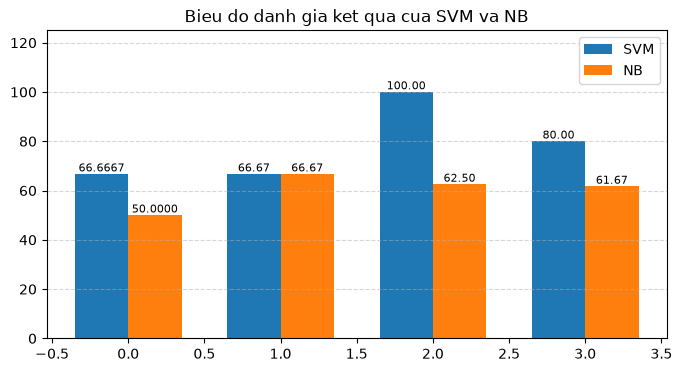

In [7]:
labels = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1_score (%)"]

svm_mean = [
    np.mean(svm_accs) * 100,
    np.mean(svm_precs) * 100,
    np.mean(svm_recs) * 100,
    np.mean(svm_f1s) * 100,
]

nb_mean = [
    np.mean(nb_accs) * 100,
    np.mean(nb_precs) * 100,
    np.mean(nb_recs) * 100,
    np.mean(nb_f1s) * 100,
]

x = np.arange(len(labels))
w = 0.35

plt.figure(figsize=(8, 4))

b1=plt.bar(x-w/2, svm_mean, width=w, label="SVM")
b2=plt.bar(x+w/2, nb_mean, width=w, label="NB")
p_svm = ax.bar(x[:-1] - w/2, svm_mean[1:], width = w, color="tab:blue", edgecolor="black", label="SVM")
p_nb = ax.bar(x[:-1] + w/2, svm_mean[1:], width = w, color="tab:orange", edgecolor="black", label="NB")
y_max = max(max(svm_mean),max(nb_mean))
plt.ylim(0,y_max*1.25)
plt.legend()
for idx,bar in enumerate(b1):
    h=bar.get_height()
    fmt=f"{h:.4f}" if idx == 0 else f"{h:.2f}"
    plt.text(bar.get_x() + bar.get_width() / 2, h, fmt, ha="center", va="bottom", fontsize=8)
for idx,bar in enumerate(b2):
    h=bar.get_height()
    fmt=f"{h:.4f}" if idx == 0 else f"{h:.2f}"
    plt.text(bar.get_x() + bar.get_width() / 2, h, fmt, ha="center", va="bottom", fontsize=8)
plt.title("Bieu do danh gia ket qua cua SVM va NB")
plt.grid(axis="y", linestyle ="--", alpha=0.5)
plt.show()